# Vegetation, surface temperature and soil moisture over a polygon with cubesip

This notebook takes an area drawn as a polygon and, for one year, retrieves three variables
from three different sources with the same few cubesip calls:

| Variable | Source | cubesip driver | Native grid |
|---|---|---|---|
| NDVI | Sentinel-2 L2A red (B04) and near infrared (B08), clouds masked with the scene classification (SCL) | `openeo` (Copernicus Data Space Ecosystem) | 10 m, UTM |
| Land-surface temperature | Landsat 8 and 9 Collection 2 Level-2 surface temperature (`lwir11`), clouds masked with `qa_pixel` | `stac` (Microsoft Planetary Computer, loaded by openEO `load_stac`) | 30 m, UTM |
| Surface soil moisture | Copernicus Land Monitoring Service SSM, Sentinel-1, Europe, 1 km daily | `openeo` (Copernicus Data Space Ecosystem) | 1 km, lat/lon |

**Why these sources.** For land-surface temperature, Landsat is the only free source that
resolves a field-sized area: 30 m pixels (resampled from the 100 m thermal band) against
1 km for Sentinel-3 SLSTR and MODIS and 3-5 km for the CLMS hourly product. The price is
fewer observations: one daytime overpass (about 10:30 local time) every 8 days with two
satellites, and only cloud-free ones count. For soil moisture, the CLMS Sentinel-1 product
at 1 km is the finest available on the back-ends cubesip reaches (ERA5-Land is about 9 km,
the global CLMS Soil Water Index 12.5 km).

Along the way the notebook uses the main parts of the package:

- `cubesip.processing.containing_geohash`: the geohash cell that holds the polygon, which
  is how cubesip addresses an area;
- `cubesip.check`: what a request would download, before downloading it;
- `cubesip.run`: download (or reuse from the cache) and open the data as xarray;
- `cubesip.processing.mask_to_polygon`: blank out everything outside the polygon;
- `cubesip.processing.regrid`: put the three variables on one grid to map them side by side.

You need a `cubesip.yaml` with a Copernicus Data Space account (`openeo` section, see
`cubesip.example.yaml`). The first run downloads about 150 MB and takes a few minutes; later
runs read the files back from `data/`.

In [1]:
import os
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shapely
import xarray as xr
from pyproj import CRS, Transformer

import cubesip
from cubesip.processing import containing_geohash, mask_to_polygon, regrid
from cubesip.spatial import find_dims, native_crs

# cubesip.yaml and data/ are in the repository root; Jupyter starts in the notebook's folder.
if Path.cwd().name == "examples":
    os.chdir(Path.cwd().parent)

# Chart colours (light theme), as in the other examples.
SURFACE = "#fcfcfb"
INK_PRIMARY = "#0b0b0b"
INK_SECONDARY = "#52514e"
INK_MUTED = "#898781"
GRID = "#e1e0d9"
AXIS = "#c3c2b7"
ACCENT = "#2a78d6"


def crs_name(ds: xr.Dataset) -> str:
    """Name of a dataset's CRS, e.g. 'WGS 84 / UTM zone 31N'."""
    return CRS.from_user_input(native_crs(ds)).name


plt.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.sans-serif": ["Segoe UI", "Helvetica Neue", "Arial", "DejaVu Sans"],
        "font.size": 10,
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
    }
)

## 1. The area: a polygon in WKT

The polygon is written as WKT in EPSG:4326 with **longitude first**, the convention of every
cubesip function that takes a geometry. This one covers a few fields of the Beauce plain,
south-west of Paris, intensively farmed cropland (mostly winter wheat, barley, rapeseed and
maize). Replace it with your own area; keep it inside Europe for the soil moisture product.

In [2]:
POLYGON_WKT = (
    "POLYGON ((1.632 48.302, 1.660 48.300, 1.665 48.318, "
    "1.652 48.334, 1.634 48.328, 1.632 48.302))"
)
YEAR = 2024

polygon = shapely.from_wkt(POLYGON_WKT)

# Area in km2, measured in the local UTM zone (31N).
to_utm = Transformer.from_crs("EPSG:4326", "EPSG:32631", always_xy=True)
polygon_utm = shapely.transform(
    polygon, lambda xy: np.column_stack(to_utm.transform(xy[:, 0], xy[:, 1]))
)
print(f"Polygon area: {polygon_utm.area / 1e6:.1f} km2")

Polygon area: 7.0 km2


cubesip requests are addressed by a [geohash](https://en.wikipedia.org/wiki/Geohash) cell
rather than a geometry: a short string that names a rectangle on the globe, and lets the
cache know that data for a cell also covers every smaller cell inside it.
`containing_geohash` finds the smallest cell that holds the whole polygon; every request
below is for that cell, and the polygon is cut out afterwards.

Geohash cell: u094v
  lon 1.6260 .. 1.6699, lat 48.2959 .. 48.3398


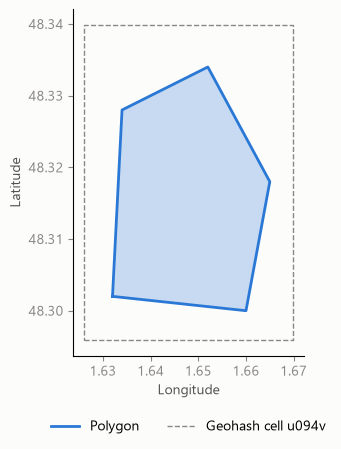

In [3]:
site = containing_geohash(POLYGON_WKT)
cell = cubesip.geohash.bbox(site)
print(f"Geohash cell: {site}")
print(f"  lon {cell.west:.4f} .. {cell.east:.4f}, lat {cell.south:.4f} .. {cell.north:.4f}")

fig, ax = plt.subplots(figsize=(4, 4.5))
ax.fill(*polygon.exterior.xy, color=ACCENT, alpha=0.25, linewidth=0)
ax.plot(*polygon.exterior.xy, color=ACCENT, linewidth=2, label="Polygon")
ax.plot(
    [cell.west, cell.east, cell.east, cell.west, cell.west],
    [cell.south, cell.south, cell.north, cell.north, cell.south],
    color=INK_MUTED,
    linewidth=1,
    linestyle="--",
    label=f"Geohash cell {site}",
)
ax.set_aspect(1 / np.cos(np.radians(polygon.centroid.y)))  # metres look square
ax.set_xlabel("Longitude", color=INK_SECONDARY)
ax.set_ylabel("Latitude", color=INK_SECONDARY)
ax.tick_params(colors=INK_MUTED)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), frameon=False, ncols=2)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.show()

## 2. The three requests, checked before downloading

A request is a plain dictionary (or a JSON file) naming the driver, the dataset, the
variables, the geohash and the period, both days included. Options are passed through to
the source: here a limit on the cloud cover of whole scenes, which skips the scenes that
are almost entirely cloudy (the remaining clouds are masked pixel by pixel below). The
Landsat collection holds Landsat 8 and 9 for 2024; a `properties` option such as
`{"platform": {"eq": "landsat-9"}}` would keep one of them.

`cubesip.check` reports, without downloading, whether the data are already cached, whether
the dataset and bands exist, and how big the download would be.

In [4]:
period = {"start": f"{YEAR}-01-01", "end": f"{YEAR}-12-31"}

ndvi_request = {
    "driver": "openeo",
    "dataset": "SENTINEL2_L2A",
    "variables": ["B04", "B08", "SCL"],
    "geohash": site,
    "time": period,
    "target_dir": "data",
    "options": {"max_cloud_cover": 80},
}

lst_request = {
    "driver": "stac",
    "dataset": "https://planetarycomputer.microsoft.com/api/stac/v1/collections/landsat-c2-l2",
    "variables": ["lwir11", "qa_pixel"],
    "geohash": site,
    "time": period,
    "target_dir": "data",
    "options": {"max_cloud_cover": 80},
}

ssm_request = {
    "driver": "openeo",
    "dataset": "CLMS_SSM_EUROPE_1KM_DAILY_V1",
    "variables": ["ssm"],
    "geohash": site,
    "time": period,
    "target_dir": "data",
}

for request in (ndvi_request, lst_request, ssm_request):
    print(cubesip.check(request), end="\n\n")

cubesip check: openeo SENTINEL2_L2A [B04, B08, SCL] @ u094v, 2024-01-01 to 2024-12-31
  status : cached (geohash u094v) in C:\Users\matte\OneDrive\local\work\cubesip\data\openeo_SENTINEL2-L2A_u094v_20240101-20241231_21245e6f.nc

cubesip check: stac https://planetarycomputer.microsoft.com/api/stac/v1/collections/landsat-c2-l2 [lwir11, qa_pixel] @ u094v, 2024-01-01 to 2024-12-31
  status : cached (geohash u094v) in C:\Users\matte\OneDrive\local\work\cubesip\data\stac_landsat-c2-l2_u094v_20240101-20241231_486e5d1a.nc

cubesip check: openeo CLMS_SSM_EUROPE_1KM_DAILY_V1 [ssm] @ u094v, 2024-01-01 to 2024-12-31
  status : cached (geohash u094v) in C:\Users\matte\OneDrive\local\work\cubesip\data\openeo_CLMS-SSM-EUROPE-1KM-DAILY-V1_u094v_20240101-20241231_3cc0f90b.nc



`cubesip.run` downloads each request, writes it to a NetCDF file in `data/` and records it
in the manifest (`data/manifest.csv`). Run the notebook again and the same calls read the
files back instead (`from_cache` is then `True`). `result.dataset` is a lazy
`xarray.Dataset` cut to the geohash cell.

In [5]:
results = {}
for name, request in [("NDVI", ndvi_request), ("LST", lst_request), ("SSM", ssm_request)]:
    result = cubesip.run(request)
    results[name] = result
    origin = "from cache" if result.from_cache else "downloaded"
    print(f"{name}: {origin}, {result.path.name}")

NDVI: from cache, openeo_SENTINEL2-L2A_u094v_20240101-20241231_21245e6f.nc


LST: from cache, stac_landsat-c2-l2_u094v_20240101-20241231_486e5d1a.nc


SSM: from cache, openeo_CLMS-SSM-EUROPE-1KM-DAILY-V1_u094v_20240101-20241231_3cc0f90b.nc


## 3. NDVI from Sentinel-2

Sentinel-2 bands come as stored by the provider (reflectance x 10 000). The scale cancels
out in NDVI = (B08 - B04) / (B08 + B04), so it can be computed on the values as they are.
Pixels are kept only when the scene classification says vegetation (4), bare soil (5) or
water (6): clouds, cloud shadows and snow are dropped.

In [6]:
s2 = results["NDVI"].dataset
print(s2)

red, nir, scl = s2["B04"], s2["B08"], s2["SCL"]
clear = scl.isin([4, 5, 6]) & ((nir + red) > 0)
ndvi = ((nir - red) / (nir + red)).where(clear)
ndvi.name = "NDVI"
print(f"\n{ndvi.sizes['t']} Sentinel-2 scenes in {YEAR}, on a {crs_name(s2)} grid")

<xarray.Dataset> Size: 139MB
Dimensions:  (t: 70, y: 495, x: 335)
Coordinates:
  * t        (t) datetime64[ns] 560B 2024-01-03 2024-01-05 ... 2024-12-23
  * y        (y) float64 4kB 5.355e+06 5.355e+06 5.355e+06 ... 5.35e+06 5.35e+06
  * x        (x) float64 3kB 3.981e+05 3.981e+05 ... 4.014e+05 4.014e+05
    crs      |S1 1B ...
Data variables:
    B04      (t, y, x) float32 46MB dask.array<chunksize=(1, 256, 256), meta=np.ndarray>
    B08      (t, y, x) float32 46MB dask.array<chunksize=(1, 256, 256), meta=np.ndarray>
    SCL      (t, y, x) float32 46MB dask.array<chunksize=(1, 256, 256), meta=np.ndarray>
Attributes:
    Conventions:  CF-1.9
    institution:  openEO platform

70 Sentinel-2 scenes in 2024, on a WGS 84 / UTM zone 31N grid


## 4. Land-surface temperature from Landsat 8 and 9

Landsat Collection 2 stores surface temperature as integers: kelvin = DN x 0.00341802 +
149.0 (the `scale` and `offset` of the STAC `raster:bands` metadata), and 0 marks missing
data. The `qa_pixel` band flags clouds bit by bit; a pixel is kept when bit 6 (clear: no
cloud, no dilated cloud) is set and bits 4 (cloud shadow) and 5 (snow) are not.

These are clear-sky daytime temperatures of the surface itself, taken around 10:30 local
time: in summer a bare or dry field is much hotter than the air above it.

In [7]:
landsat = results["LST"].dataset
print(landsat)

qa = landsat["qa_pixel"].fillna(1).astype("uint16")  # 1 = fill in QA_PIXEL
bit = lambda n: (qa & (1 << n)) > 0  # noqa: E731
clear_sky = bit(6) & ~bit(4) & ~bit(5)

dn = landsat["lwir11"]
lst = (dn * 0.00341802 + 149.0 - 273.15).where(clear_sky & (dn > 0))
lst.name = "LST"
print(f"\n{lst.sizes['t']} Landsat scenes in {YEAR}, on a {crs_name(landsat)} grid")

<xarray.Dataset> Size: 15MB
Dimensions:   (t: 49, y: 166, x: 113)
Coordinates:
  * t         (t) datetime64[ns] 392B 2024-01-14 2024-01-15 ... 2024-12-15
  * y         (y) float64 1kB 5.355e+06 5.355e+06 ... 5.35e+06 5.35e+06
  * x         (x) float64 904B 3.981e+05 3.981e+05 ... 4.014e+05 4.014e+05
    crs       |S1 1B ...
Data variables:
    lwir11    (t, y, x) float64 7MB dask.array<chunksize=(1, 166, 113), meta=np.ndarray>
    qa_pixel  (t, y, x) float64 7MB dask.array<chunksize=(1, 166, 113), meta=np.ndarray>
Attributes:
    Conventions:  CF-1.9
    institution:  openEO platform

49 Landsat scenes in 2024, on a WGS 84 / UTM zone 31N grid


## 5. Surface soil moisture from Sentinel-1

The CLMS SSM product gives the moisture of the top few centimetres of soil as a percentage
of saturation (0 = completely dry, 100 = saturated), derived from Sentinel-1 radar
backscatter, so clouds do not matter. A value exists only on days with a Sentinel-1 pass.

In [8]:
clms = results["SSM"].dataset
print(clms)

ssm = clms["ssm"]
ssm = ssm.where((ssm >= 0) & (ssm <= 100))  # anything else is a flag or no data
ssm.name = "SSM"
n_days = int(ssm.notnull().any(dim=[d for d in ssm.dims if d != "t"]).sum())
print(f"\n{n_days} days with soil moisture in {YEAR}, on a {crs_name(clms)} grid")

<xarray.Dataset> Size: 18kB
Dimensions:  (t: 119, y: 6, x: 6)
Coordinates:
  * t        (t) datetime64[ns] 952B 2024-01-02 2024-01-06 ... 2024-12-31
  * y        (y) float64 48B 48.34 48.33 48.33 48.32 48.31 48.3
  * x        (x) float64 48B 1.629 1.638 1.647 1.656 1.665 1.674
    crs      |S1 1B ...
Data variables:
    ssm      (t, y, x) float32 17kB dask.array<chunksize=(56, 6, 6), meta=np.ndarray>
Attributes:
    Conventions:  CF-1.9
    institution:  openEO platform

119 days with soil moisture in 2024, on a WGS 84 grid


## 6. Annual maps over the polygon

Each variable is first averaged over the year **per pixel, as the mean of its monthly
means**, so that the many clear summer scenes of Sentinel-2 and Landsat do not outweigh the
few winter ones. Months without any valid observation for a pixel are skipped.

The three annual means are on three different grids (10 m UTM, 30 m UTM, 1 km lat/lon).
`regrid` puts Landsat and soil moisture on the Sentinel-2 grid, with nearest-neighbour
resampling so that every source keeps its own pixel size on the map: each 1 km soil
moisture cell becomes a block of 10 m cells. `mask_to_polygon` then blanks out every cell
whose centre is outside the polygon.

On the land-surface temperature map, the 30 m Landsat pixels show patches of about
100 m: the thermal sensor's own resolution, which USGS resamples to 30 m. Each colour scale
spans the values inside the polygon, so the soil moisture map shows differences of a few
percent between 1 km cells.

In [9]:
def annual_mean(da: xr.DataArray) -> xr.DataArray:
    """Mean of the monthly means of each pixel."""
    return da.resample(t="MS").mean().mean("t")


annual = {
    "NDVI": annual_mean(ndvi).compute(),
    "LST": annual_mean(lst).compute(),
    "SSM": annual_mean(ssm).compute(),
}

# Common grid: Sentinel-2's (10 m, UTM). A DataArray in gives a DataArray out.
on_s2 = {
    "NDVI": annual["NDVI"],
    "LST": regrid(annual["LST"], annual["NDVI"]),
    "SSM": regrid(annual["SSM"], annual["NDVI"]),
}
maps = {name: mask_to_polygon(da, POLYGON_WKT) for name, da in on_s2.items()}

for name, da in maps.items():
    print(f"{name}: polygon mean of the annual map {float(da.mean()):.2f}")

NDVI: polygon mean of the annual map 0.42
LST: polygon mean of the annual map 19.78
SSM: polygon mean of the annual map 64.65


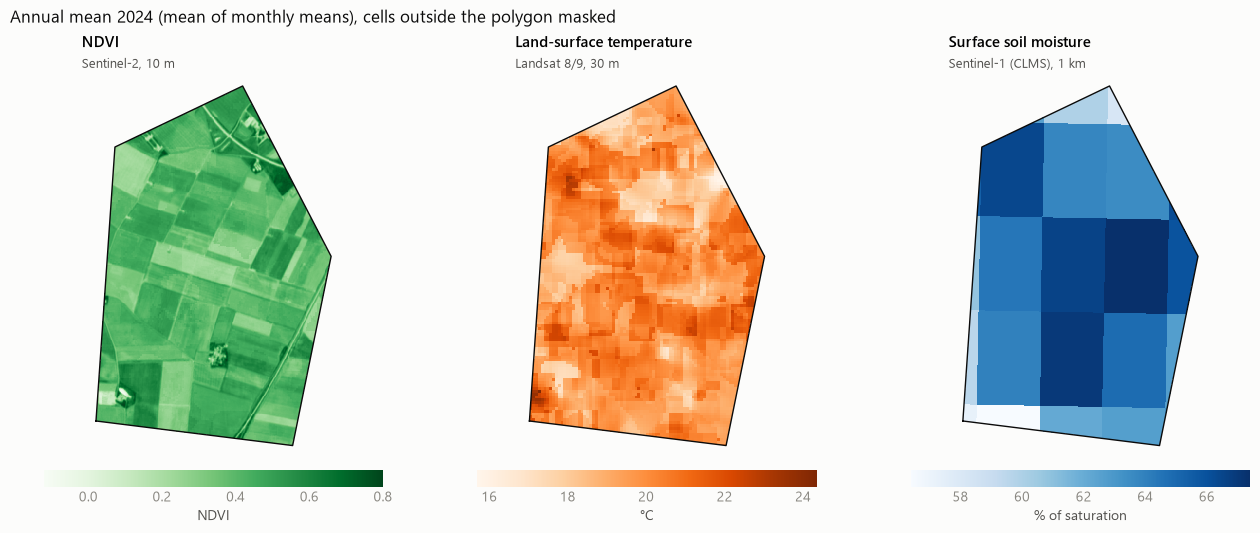

In [10]:
MAP_STYLE = {
    "NDVI": ("Greens", "NDVI", "Sentinel-2, 10 m"),
    "LST": ("Oranges", "°C", "Landsat 8/9, 30 m"),
    "SSM": ("Blues", "% of saturation", "Sentinel-1 (CLMS), 1 km"),
}
TITLES = {"NDVI": "NDVI", "LST": "Land-surface temperature", "SSM": "Surface soil moisture"}

# Show only the polygon's surroundings, in the Sentinel-2 grid's CRS.
grid_crs = native_crs(s2)
to_grid = Transformer.from_crs("EPSG:4326", grid_crs, always_xy=True)
outline = shapely.transform(
    shapely.segmentize(polygon, 0.001),
    lambda xy: np.column_stack(to_grid.transform(xy[:, 0], xy[:, 1])),
)
west, south, east, north = outline.buffer(150).bounds

fig, axes = plt.subplots(1, 3, figsize=(13, 5.2), layout="constrained")
for ax, (name, da) in zip(axes, maps.items(), strict=True):
    cmap, units, source = MAP_STYLE[name]
    dims = find_dims(da.to_dataset(name="v"))
    mesh = ax.pcolormesh(da[dims.x], da[dims.y], da, cmap=cmap, shading="nearest")
    ax.plot(*outline.exterior.xy, color=INK_PRIMARY, linewidth=1)
    ax.set_xlim(west, east)
    ax.set_ylim(south, north)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_title(f"{TITLES[name]}\n", loc="left", fontsize=11, fontweight="semibold")
    ax.text(0, 1.01, source, transform=ax.transAxes, color=INK_SECONDARY, fontsize=9)
    bar = fig.colorbar(mesh, ax=ax, orientation="horizontal", shrink=0.8, pad=0.02)
    bar.set_label(units, color=INK_SECONDARY)
    bar.outline.set_visible(False)
    bar.ax.tick_params(colors=INK_MUTED, length=0)
fig.suptitle(
    f"Annual mean {YEAR} (mean of monthly means), cells outside the polygon masked",
    x=0.01,
    ha="left",
    color=INK_PRIMARY,
    fontsize=12,
)
plt.show()

## 7. Time series averaged over the polygon

For the time series each variable stays on its own grid. `mask_to_polygon` keeps the cells
inside the polygon, then the cells are averaged for each date. A date counts only when at
least half of the polygon's cells have a valid value, so a scene with a cloud over half of
the area does not stand for the whole polygon.

The soil moisture cells (1 km) are large compared with the polygon, so for them
`all_touched=True` keeps every cell the polygon touches rather than only those whose centre
is inside.

In [11]:
def polygon_series(da: xr.DataArray, min_valid: float = 0.5, **mask_options) -> pd.Series:
    """Mean over the polygon's cells for each date with at least ``min_valid`` of them valid."""
    dims = find_dims(da.to_dataset(name="v"))
    space = [dims.y, dims.x]
    inside = mask_to_polygon(xr.ones_like(da.isel(t=0, drop=True)), POLYGON_WKT, **mask_options)
    n_inside = int(inside.notnull().sum())
    masked = mask_to_polygon(da, POLYGON_WKT, **mask_options)
    valid = masked.notnull().sum(space) / n_inside
    series = masked.mean(space).where(valid >= min_valid).to_series().dropna()
    series.index = pd.DatetimeIndex(series.index).normalize()
    return series.groupby(level=0).mean()  # one value per day


series = {
    "NDVI": polygon_series(ndvi),
    "LST": polygon_series(lst),
    "SSM": polygon_series(ssm, all_touched=True),
}
monthly = {name: s.resample("MS").mean() for name, s in series.items()}

summary = pd.DataFrame(
    {
        "dates_used": {name: len(s) for name, s in series.items()},
        "annual_mean_of_monthly_means": {name: m.mean() for name, m in monthly.items()},
        "min": {name: s.min() for name, s in series.items()},
        "max": {name: s.max() for name, s in series.items()},
    }
).round(2)
summary

,dates_used,annual_mean_of_monthly_means,min,max
NDVI,22,0.41,0.25,0.68
LST,19,19.21,5.59,38.79
SSM,119,63.09,1.74,99.09


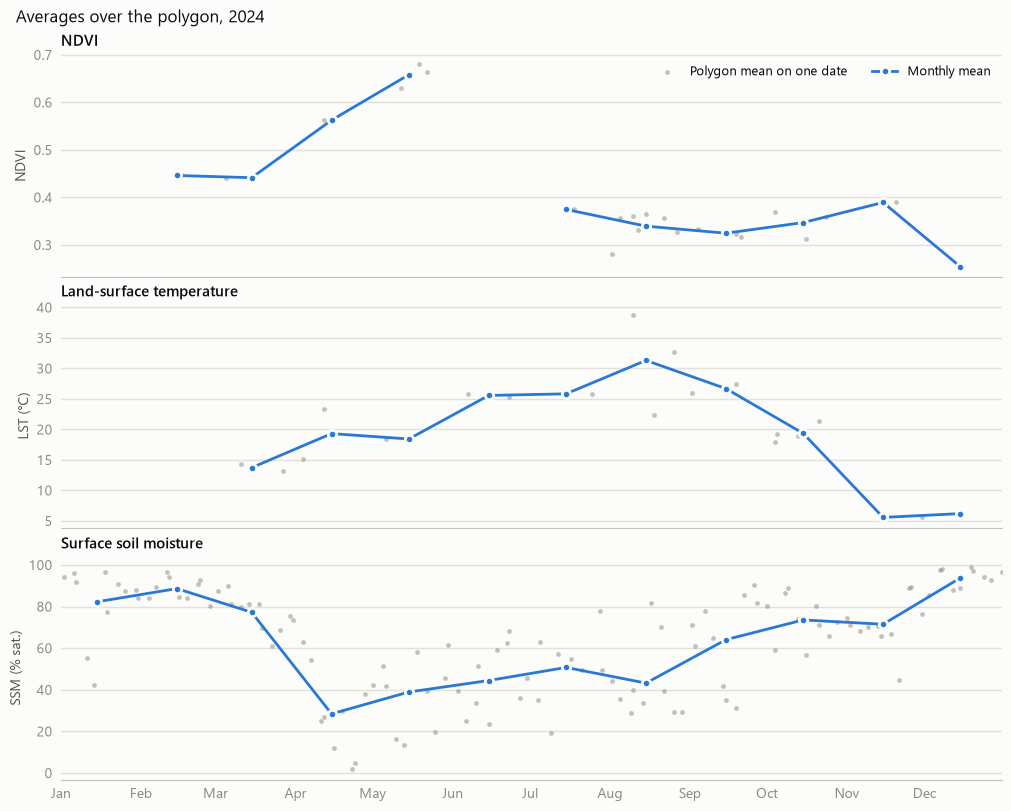

In [12]:
SERIES_UNITS = {"NDVI": "NDVI", "LST": "LST (°C)", "SSM": "SSM (% sat.)"}

fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True, layout="constrained")
for ax, name in zip(axes, series, strict=True):
    s, m = series[name], monthly[name]
    ax.scatter(s.index, s.values, s=12, color=INK_MUTED, alpha=0.5, linewidths=0,
               label="Polygon mean on one date", zorder=2)
    mid_month = m.index.shift(14, freq="D")
    ax.plot(mid_month, m.values, color=ACCENT, linewidth=2, marker="o", markersize=6,
            markerfacecolor=ACCENT, markeredgecolor=SURFACE, markeredgewidth=2,
            label="Monthly mean", zorder=3)
    ax.set_title(TITLES[name], loc="left", fontsize=11, fontweight="semibold",
                 color=INK_PRIMARY)
    ax.set_ylabel(SERIES_UNITS[name], color=INK_SECONDARY)
    ax.yaxis.grid(True, color=GRID, linewidth=1)
    ax.set_axisbelow(True)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(AXIS)
    ax.tick_params(colors=INK_MUTED, length=0, pad=6)

axes[0].legend(loc="upper right", frameon=False, ncols=2, fontsize=9)
axes[-1].set_xlim(pd.Timestamp(f"{YEAR}-01-01"), pd.Timestamp(f"{YEAR}-12-31"))
axes[-1].xaxis.set_major_locator(mdates.MonthLocator())
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b"))
fig.suptitle(f"Averages over the polygon, {YEAR}", x=0.01, ha="left", fontsize=12,
             color=INK_PRIMARY)
plt.show()

## 8. What cubesip kept

Every download added one row per variable to the manifest. The next request for this cell,
or for any smaller cell inside it (a single field, say), for a period within this year, is
served from these files without downloading.

In [13]:
manifest = pd.read_csv(cubesip.load_config().manifest)
manifest[manifest["geohash"] == site][
    ["driver", "dataset", "variable", "geohash", "time_start", "time_end", "file_size_bytes"]
]

,driver,dataset,variable,geohash,time_start,time_end,file_size_bytes
32,openeo,CLMS_SSM_EUROPE_1KM_DAILY_V1,ssm,u094v,2024-01-01,2024-12-31,24158
33,stac,https://planetarycomputer.microsoft.com/api/st...,lwir11,u094v,2024-01-01,2024-12-31,1957686
34,stac,https://planetarycomputer.microsoft.com/api/st...,qa_pixel,u094v,2024-01-01,2024-12-31,1957686
35,openeo,SENTINEL2_L2A,B04,u094v,2024-01-01,2024-12-31,33566913
36,openeo,SENTINEL2_L2A,B08,u094v,2024-01-01,2024-12-31,33566913
37,openeo,SENTINEL2_L2A,SCL,u094v,2024-01-01,2024-12-31,33566913


In [14]:
# A field inside the polygon has a longer geohash inside the cell: its request is a cache hit.
field = cubesip.geohash.encode(polygon.centroid.y, polygon.centroid.x, precision=7)
print(cubesip.check({**ssm_request, "geohash": field,
                     "time": {"start": f"{YEAR}-06-01", "end": f"{YEAR}-08-31"}}))

cubesip check: openeo CLMS_SSM_EUROPE_1KM_DAILY_V1 [ssm] @ u094v7x, 2024-06-01 to 2024-08-31
  status : cached (geohash u094v) in C:\Users\matte\OneDrive\local\work\cubesip\data\openeo_CLMS-SSM-EUROPE-1KM-DAILY-V1_u094v_20240101-20241231_3cc0f90b.nc
